# Bayesian VAR — 6-Month ISM Forecast (v2: `bvar` package + train/test evaluation)

This replaces the from-scratch equation-by-equation BVAR with the **`bvar`** PyPI package (installed via `pip install bvar`), which implements a proper joint Normal-Inverse-Wishart Minnesota-prior BVAR (Chan, 2020), with sum-of-coefficients and single-unit-root dummy priors and marginal-likelihood hyperparameter tuning (Giannone, Lenza & Primiceri, 2015), plus native COVID-19 volatility-dummy handling (Lenza & Primiceri, 2020). This is a materially better estimator than the independent-equation approximation used before, and it comes with proper tooling for the second ask: **holding out a genuine test period and evaluating out-of-sample accuracy against naive benchmarks**, rather than just fitting and forecasting blind.

**Environment note:** `pip install bvar` pulled in `numpy 2.3.5` (from 2.4.4). This is unrelated to a pre-existing, broken `jax` installation in this Anaconda environment (its `ml_dtypes` binary was compiled against numpy 1.x and can't load under any numpy 2.x, so it wasn't functional before this either — e.g. `tensorflow-intel` already required `numpy<2.0`). Because `optimise_hyperparameters()` defaults to a JAX backend when available, we explicitly pass `optimisation_backend='numpy'` everywhere to force the pure NumPy/SciPy fallback.

**What changed from v1, and why:**
- **Variables are now fed as (log-)levels, not manually differenced.** This package's sum-of-coefficients / single-unit-root dummy priors are specifically designed to regularize non-stationary levels data (the standard modern BVAR workflow — e.g. NY Fed / ECB BEAR toolkits). Feeding it already-differenced growth rates would waste that machinery and mismatch its random-walk prior convention.
- **COVID handling moved from manual Hampel-filter smoothing to the package's built-in COVID dummy** (`covid=True`, dates Feb–Dec 2020). This scales/absorbs the pandemic-era shock at estimation time rather than editing the observed data — more principled, and it's what the library is built around. We therefore read from `Raw_Monthly`, not the `Smoothed_Monthly` sheet built earlier.
- **Same variable set as before**: ISM (target), T10Y2Y spread, Jobless Claims, SPX, NFCI, Building Permits. Copper is still dropped (near-zero correlation with ISM, and a 12-month stale trailing gap).
- Trending, strictly-positive series (Jobless Claims, SPX, Building Permits) enter in **log-levels**; rate/index series that can be negative (ISM, T10Y2Y spread, NFCI) enter in **raw levels**.

**Train/test design:** the last 24 months are held out entirely from estimation and hyperparameter tuning. The lag order `p` and prior tightness are chosen using only the training period, then scored on the untouched test period against two naive benchmarks (random walk, historical mean). Only after that evaluation is the final model refit on the full sample to produce the actual 6-month-ahead forecast.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bvar

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (11, 4)

COMBINED_FILE = 'Growth_monthly_combined.xlsx'
OUTPUT_FILE = 'ISM_BVAR_Forecast.xlsx'

FORECAST_HORIZON = 9
TEST_SIZE = 24
P_GRID = [3, 6, 12]
COVID_DATES = ['2020-02', '2020-12']
N_DRAWS_SEARCH = 1000
N_DRAWS_FINAL = 3000
RANDOM_STATE = 42
BACKEND = 'numpy'  # jax is broken in this environment; force the NumPy/SciPy fallback

# Theme colors
navy_blue = '#13294B'
illini_orange = '#E84A27'
slate_grey = '#686F73'

## 1. Load raw monthly data and build the (log-)levels system

In [2]:
panel = pd.read_excel(COMBINED_FILE, sheet_name='Raw_Monthly', index_col=0, parse_dates=True)

use_cols = ['ISM_NEWORDERS', 'T10Y2Y_EOM', 'ICSA_AVG', 'SPX_EOM', 'NFCI_AVG', 'PERMIT']
raw = panel[use_cols].dropna()

Z = pd.DataFrame(index=raw.index)
Z['ISM'] = raw['ISM_NEWORDERS']          # levels
Z['T10Y2Y'] = raw['T10Y2Y_EOM']          # levels
Z['NFCI'] = raw['NFCI_AVG']              # levels
Z['ICSA'] = np.log(raw['ICSA_AVG'])      # log-levels
Z['SPX'] = np.log(raw['SPX_EOM'])        # log-levels
Z['PERMIT'] = np.log(raw['PERMIT'])      # log-levels
Z.index = Z.index.to_period('M')

DATA_TRANSFORMATION = {'ISM': 'levels', 'T10Y2Y': 'levels', 'NFCI': 'levels',
                        'ICSA': 'logs', 'SPX': 'logs', 'PERMIT': 'logs'}
LOG_VARS_TRANSFORM = {k: None for k, v in DATA_TRANSFORMATION.items() if v == 'logs'}

print(f"Sample: {Z.index.min()} to {Z.index.max()}  ({len(Z)} months)")
print(f"Dropped variable: COPPER (near-zero ISM correlation + 12-month stale trailing gap)")
Z.tail()

Sample: 1996-09 to 2026-08  (360 months)
Dropped variable: COPPER (near-zero ISM correlation + 12-month stale trailing gap)


,ISM,T10Y2Y,NFCI,ICSA,SPX,PERMIT
date,,,,,,
2026-04,54.1,0.52,-0.47950,12.244091,8.883087,7.260523
2026-05,56.8,0.47,-0.50580,12.262453,8.933276,7.251345
2026-06,56.0,0.30,-0.50700,12.312682,8.922573,7.225481
2026-07,56.7,0.47,-0.52700,12.222192,8.921287,7.267525
2026-08,53.7,0.41,-0.54875,12.235631,8.947174,7.239933


## 2. Train / test split

The last 24 months are reserved purely for evaluation — never touched during estimation or hyperparameter tuning.

In [3]:
train = Z.iloc[:-TEST_SIZE]
test = Z.iloc[-TEST_SIZE:]

print(f"Train: {train.index.min()} to {train.index.max()}  ({len(train)} months)")
print(f"Test:  {test.index.min()} to {test.index.max()}  ({len(test)} months, held out)")

Train: 1996-09 to 2024-08  (336 months)
Test:  2024-09 to 2026-08  (24 months, held out)


## 3. Tune lag order + prior hyperparameters on the training set only

For each candidate lag order `p`, tune `(c1, c3, mu, theta)` by marginal-likelihood maximisation on `train`, fit the posterior, then forecast the entire 24-month test horizon in one shot from the end of training. This is a genuine out-of-sample multi-step forecast — the test actuals are never used for fitting or tuning.

In [4]:
def fit_and_forecast(data_df, horizon, p, n_draws, nb_restart=1, random_state=RANDOM_STATE):
    model = bvar.NaturalConjugate(minnesota=True, soc=True, sur=True,
                                   covid=True, covid_dates=COVID_DATES)
    b = bvar.BVAR(n_lags=p, model=model, stationary=False,
                  optimisation_method='ml', random_state=random_state)
    b.optimise_hyperparameters(data_df, nb_restart=nb_restart,
                                optimisation_backend=BACKEND, random_state=random_state)
    b.sample(data_df, N_draws=n_draws, data_transformation=DATA_TRANSFORMATION,
              progressbar=False, random_state=random_state)
    b.forecast(H=horizon, N_draws=n_draws, format=True,
               quantiles=[0.05, 0.16, 0.5, 0.84, 0.95],
               transformations=LOG_VARS_TRANSFORM, progressbar=False, random_state=random_state)
    return b


def extract_variable_forecast(b, variable, horizon):
    df = b.df_forecasts_unconditional
    sub = df[df['variable'] == variable]
    piv = sub.pivot(index='date', columns='quantile', values='value')
    return piv.tail(horizon)


def rmse(a, f):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))


def mae(a, f):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(f))))


candidate_fits = {}
candidate_ism_forecasts = {}
actual_test_ism = test['ISM'].to_numpy()

for p in P_GRID:
    print(f"Fitting p={p} ...")
    b = fit_and_forecast(train, TEST_SIZE, p, N_DRAWS_SEARCH)
    ism_fc = extract_variable_forecast(b, 'ISM', TEST_SIZE)
    candidate_fits[p] = b
    candidate_ism_forecasts[p] = ism_fc
    print(f"  tuned pars: c1={b.model.pars.c1:.3f} c3={b.model.pars.c3:.3f} "
          f"mu={b.model.pars.mu:.3f} theta={b.model.pars.theta:.3f}")

Fitting p=3 ...


  tuned pars: c1=0.310 c3=2.288 mu=1.349 theta=0.272
Fitting p=6 ...


  tuned pars: c1=0.371 c3=3.315 mu=1.380 theta=0.282
Fitting p=12 ...


  tuned pars: c1=0.318 c3=2.945 mu=1.251 theta=0.213


## 4. Score candidates on the held-out test set, vs. naive benchmarks

In [5]:
naive_rw = np.full(TEST_SIZE, train['ISM'].iloc[-1])
naive_mean = np.full(TEST_SIZE, train['ISM'].mean())

rows = []
for p in P_GRID:
    median_fc = candidate_ism_forecasts[p][0.5].to_numpy()
    rows.append({
        'model': f'BVAR p={p}',
        'rmse_24m': rmse(actual_test_ism, median_fc),
        'mae_24m': mae(actual_test_ism, median_fc),
        'rmse_h6': rmse(actual_test_ism[:6], median_fc[:6]),
        'mae_h6': mae(actual_test_ism[:6], median_fc[:6]),
    })

rows.append({'model': 'naive_random_walk',
             'rmse_24m': rmse(actual_test_ism, naive_rw), 'mae_24m': mae(actual_test_ism, naive_rw),
             'rmse_h6': rmse(actual_test_ism[:6], naive_rw[:6]), 'mae_h6': mae(actual_test_ism[:6], naive_rw[:6])})
rows.append({'model': 'naive_historical_mean',
             'rmse_24m': rmse(actual_test_ism, naive_mean), 'mae_24m': mae(actual_test_ism, naive_mean),
             'rmse_h6': rmse(actual_test_ism[:6], naive_mean[:6]), 'mae_h6': mae(actual_test_ism[:6], naive_mean[:6])})

comparison = pd.DataFrame(rows).sort_values('rmse_24m').reset_index(drop=True)
comparison

,model,rmse_24m,mae_24m,rmse_h6,mae_h6
0,BVAR p=12,3.321605,2.864212,2.116069,1.723497
1,BVAR p=6,3.875420,3.022809,2.576634,1.908283
2,BVAR p=3,4.267652,3.226027,3.106473,2.416971
3,naive_historical_mean,5.582618,4.761806,5.835894,5.327381
4,naive_random_walk,6.455263,5.270833,4.742011,4.100000


In [6]:
bvar_rows = comparison[comparison['model'].str.startswith('BVAR')]
best_row = bvar_rows.sort_values('rmse_24m').iloc[0]
P_FINAL = int(best_row['model'].split('=')[1])

best_naive_rmse = comparison[comparison['model'].str.startswith('naive')]['rmse_24m'].min()
print(f"Selected lag order: p={P_FINAL} (test RMSE over 24 months: {best_row['rmse_24m']:.3f})")
print(f"Best naive benchmark RMSE: {best_naive_rmse:.3f}")
if best_row['rmse_24m'] < best_naive_rmse:
    print(f"=> BVAR beats the best naive benchmark by {100*(1 - best_row['rmse_24m']/best_naive_rmse):.1f}% (RMSE).")
else:
    print("=> WARNING: BVAR does NOT beat the best naive benchmark on this test window.")

Selected lag order: p=12 (test RMSE over 24 months: 3.322)
Best naive benchmark RMSE: 5.583
=> BVAR beats the best naive benchmark by 40.5% (RMSE).


### Test-period forecast vs. actual

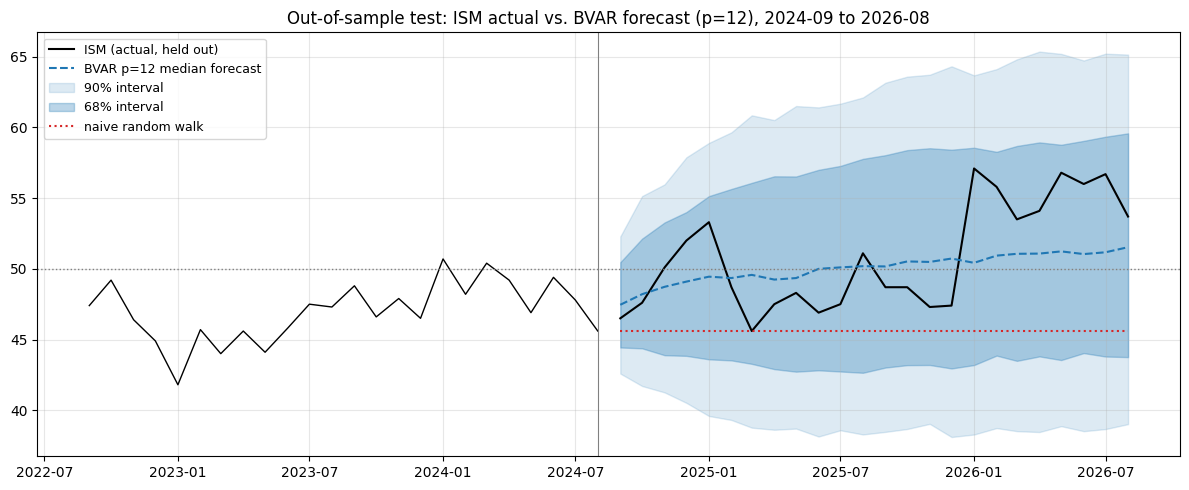

In [7]:
best_fc = candidate_ism_forecasts[P_FINAL]
dates_test = test.index.to_timestamp()
hist_tail_dates = train.index[-24:].to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_tail_dates, train['ISM'].iloc[-24:], color='black', linewidth=1)
ax.plot(dates_test, actual_test_ism, color='black', linewidth=1.5, label='ISM (actual, held out)')
ax.plot(dates_test, best_fc[0.5].to_numpy(), color='tab:blue', linestyle='--', label=f'BVAR p={P_FINAL} median forecast')
ax.fill_between(dates_test, best_fc[0.05], best_fc[0.95], color='tab:blue', alpha=0.15, label='90% interval')
ax.fill_between(dates_test, best_fc[0.16], best_fc[0.84], color='tab:blue', alpha=0.3, label='68% interval')
ax.plot(dates_test, naive_rw, color='tab:red', linestyle=':', label='naive random walk')
ax.axhline(50, color='grey', linestyle=':', linewidth=1)
ax.axvline(train.index[-1].to_timestamp(), color='grey', linewidth=0.8)
ax.set_title(f'Out-of-sample test: ISM actual vs. BVAR forecast (p={P_FINAL}), {test.index.min()} to {test.index.max()}')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Point forecast only (no bands)

Same test-period comparison as above, decluttered to just the two lines that matter for a direct actual-vs-predicted check — the posterior **median** is the BVAR's single point forecast, the same role a point estimate plays in an AR model. The interval bands above are extra Bayesian uncertainty quantification, not a substitute for a single predicted value.

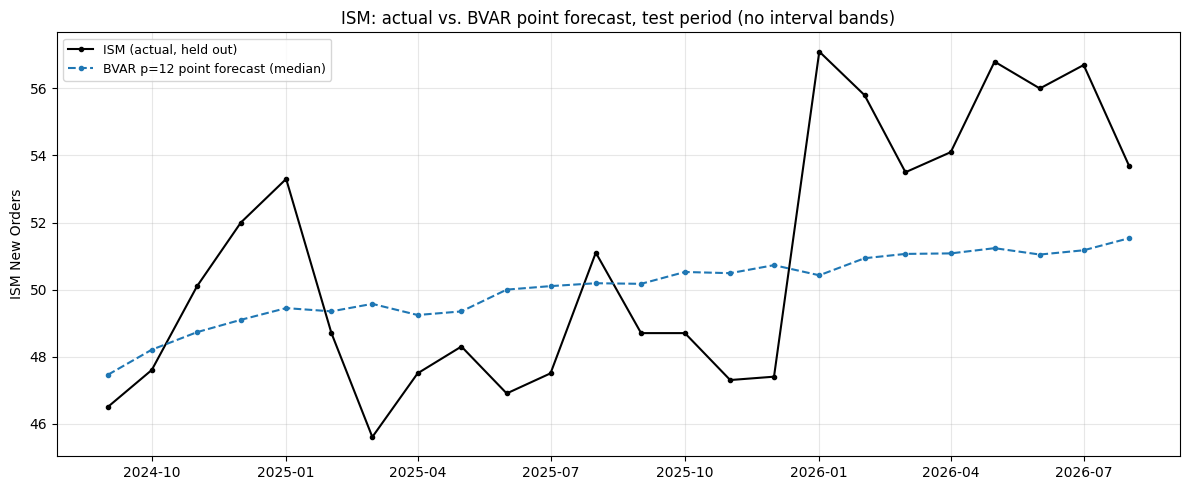

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates_test, actual_test_ism, color='black', marker='o', markersize=3, linewidth=1.5, label='ISM (actual, held out)')
ax.plot(dates_test, best_fc[0.5].to_numpy(), color='tab:blue', marker='o', markersize=3, linewidth=1.5, linestyle='--',
        label=f'BVAR p={P_FINAL} point forecast (median)')
ax.set_title('ISM: actual vs. BVAR point forecast, test period (no interval bands)')
ax.set_ylabel('ISM New Orders')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Accuracy by forecast horizon
How error grows from 1 month out to 24 months out, for the selected BVAR vs. the naive random walk.

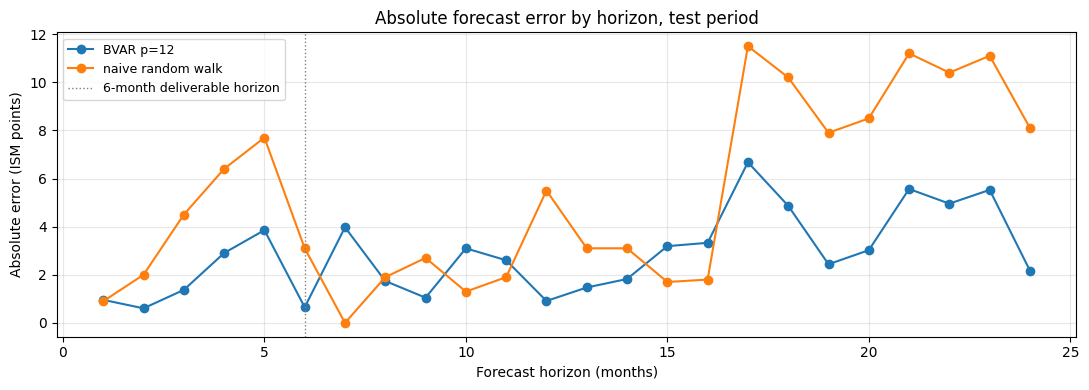

In [9]:
median_fc_best = best_fc[0.5].to_numpy()
horizon_errors = pd.DataFrame({
    'horizon': np.arange(1, TEST_SIZE + 1),
    'abs_error_bvar': np.abs(actual_test_ism - median_fc_best),
    'abs_error_naive_rw': np.abs(actual_test_ism - naive_rw),
})

fig, ax = plt.subplots()
ax.plot(horizon_errors['horizon'], horizon_errors['abs_error_bvar'], marker='o', label=f'BVAR p={P_FINAL}')
ax.plot(horizon_errors['horizon'], horizon_errors['abs_error_naive_rw'], marker='o', label='naive random walk')
ax.axvline(6, color='grey', linestyle=':', linewidth=1, label='6-month deliverable horizon')
ax.set_xlabel('Forecast horizon (months)')
ax.set_ylabel('Absolute error (ISM points)')
ax.set_title('Absolute forecast error by horizon, test period')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Refit on the full sample and forecast 6 genuine future months

With `p` chosen from the held-out test, refit on all available data (train + test) and re-tune hyperparameters on the full sample before producing the real forecast beyond the last observed month.

In [10]:
final_b = fit_and_forecast(Z, FORECAST_HORIZON, P_FINAL, N_DRAWS_FINAL, nb_restart=2)

print(f"Final tuned pars: c1={final_b.model.pars.c1:.3f} c3={final_b.model.pars.c3:.3f} "
      f"mu={final_b.model.pars.mu:.3f} theta={final_b.model.pars.theta:.3f}")

ism_forecast = extract_variable_forecast(final_b, 'ISM', FORECAST_HORIZON)
ism_forecast.columns = ['p05', 'p16', 'median', 'p84', 'p95']
ism_forecast.index = ism_forecast.index.to_timestamp()
ism_forecast

Final tuned pars: c1=0.331 c3=2.980 mu=1.247 theta=0.218


,p05,p16,median,p84,p95
date,,,,,
2026-09-01,49.173340,51.181753,54.102379,57.096533,59.064755
2026-10-01,47.869816,50.468612,54.249907,57.776250,60.245018
2026-11-01,46.703306,49.520811,54.101844,58.388468,61.293647
2026-12-01,45.232949,48.441607,53.690413,58.857065,61.982718
2027-01-01,44.189085,47.827490,53.385607,59.052786,62.868031
2027-02-01,43.391548,47.276283,53.119003,59.330376,62.985805
2027-03-01,43.070019,46.786970,52.985150,59.127059,63.234347
2027-04-01,41.945173,46.318719,52.693730,58.961366,63.374036
2027-05-01,41.772656,46.024746,52.325642,58.981262,63.193394


### Fan chart

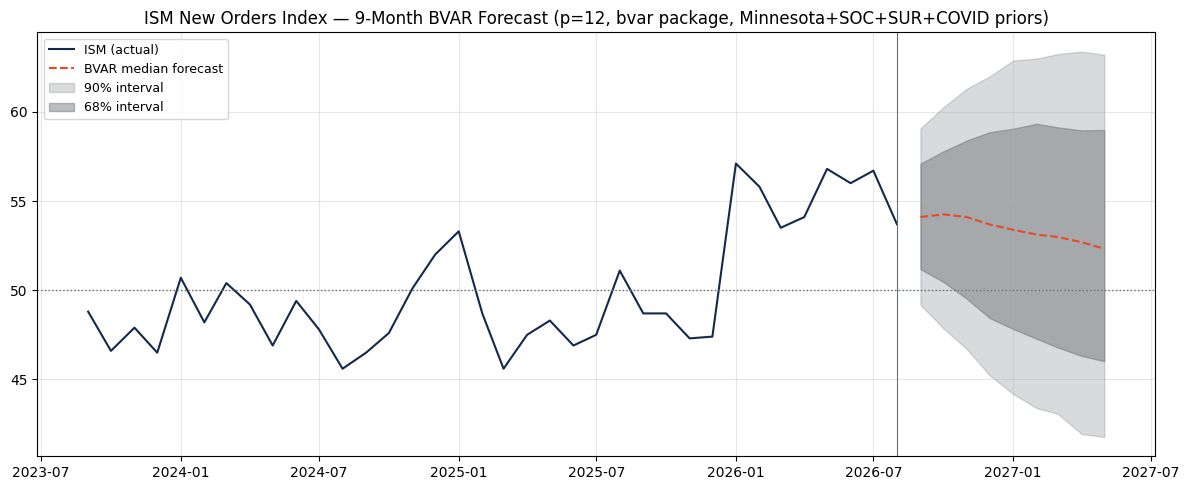

In [11]:
hist_tail = Z['ISM'].iloc[-36:]
hist_tail_dates = hist_tail.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_tail_dates, hist_tail.values, color=navy_blue, label='ISM (actual)')
ax.plot(ism_forecast.index, ism_forecast['median'], color=illini_orange, linestyle='--', label='BVAR median forecast')
ax.fill_between(ism_forecast.index, ism_forecast['p05'], ism_forecast['p95'], color=slate_grey, alpha=0.25, label='90% interval')
ax.fill_between(ism_forecast.index, ism_forecast['p16'], ism_forecast['p84'], color=slate_grey, alpha=0.45, label='68% interval')
ax.axhline(50, color=slate_grey, linestyle=':', linewidth=1)
ax.axvline(Z.index[-1].to_timestamp(), color=slate_grey, linewidth=0.8)
ax.set_title(f'ISM New Orders Index — {FORECAST_HORIZON}-Month BVAR Forecast (p={P_FINAL}, bvar package, Minnesota+SOC+SUR+COVID priors)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Diagnostics: ISM equation coefficients (final model)

Posterior mean and std (computed empirically from the posterior draws), for each regressor in the ISM equation, ranked by an informal shrinkage ratio (mean / std).

In [12]:
n, k = final_b.n, final_b.k
ism_idx = list(Z.columns).index('ISM')
h_covid = len(final_b.covid_indices)

regressor_names = ['const']
for lag in range(1, P_FINAL + 1):
    for col in Z.columns:
        regressor_names.append(f'{col}_L{lag}')
regressor_names += [f'covid_dummy_{i+1}' for i in range(h_covid)]

beta_draws_reshaped = final_b.beta.reshape(final_b.N_draws, n, k)
ism_beta_draws = beta_draws_reshaped[:, ism_idx, :]

ism_coefs = pd.DataFrame({
    'regressor': regressor_names,
    'posterior_mean': ism_beta_draws.mean(axis=0),
    'posterior_std': ism_beta_draws.std(axis=0),
})
ism_coefs['ratio'] = ism_coefs['posterior_mean'] / ism_coefs['posterior_std']
ism_coefs = ism_coefs.sort_values('ratio', key=abs, ascending=False)
ism_coefs.head(15)

,regressor,posterior_mean,posterior_std,ratio
1,ISM_L1,0.694971,0.051951,13.377425
5,SPX_L1,12.898970,3.727652,3.460347
3,NFCI_L1,-3.973640,1.463038,-2.716020
74,covid_dummy_2,-7.104447,2.834137,-2.506741
4,ICSA_L1,-7.655067,3.208224,-2.386076
11,SPX_L2,-8.754372,4.057935,-2.157346
77,covid_dummy_5,14.752887,7.028217,2.099094
80,covid_dummy_8,-10.089721,4.885282,-2.065330
10,ICSA_L2,7.380639,3.703960,1.992634
13,ISM_L3,0.070172,0.041010,1.711102


### Predictor weight chart — which variables actually drive the ISM forecast

Raw posterior-mean coefficients aren't comparable across variables here — `Z` mixes raw levels (ISM, NFCI, T10Y2Y) with log-levels (SPX, ICSA, PERMIT), so a coefficient on log-SPX and a coefficient on level-ISM are in different units. To get a fair "relative weight" comparison, each coefficient is scaled by that variable's own in-sample standard deviation, giving the effect of a typical (1-std) move in that variable on ISM — comparable across variables regardless of native units. COVID dummies (outlier controls, not macro predictors) are excluded.

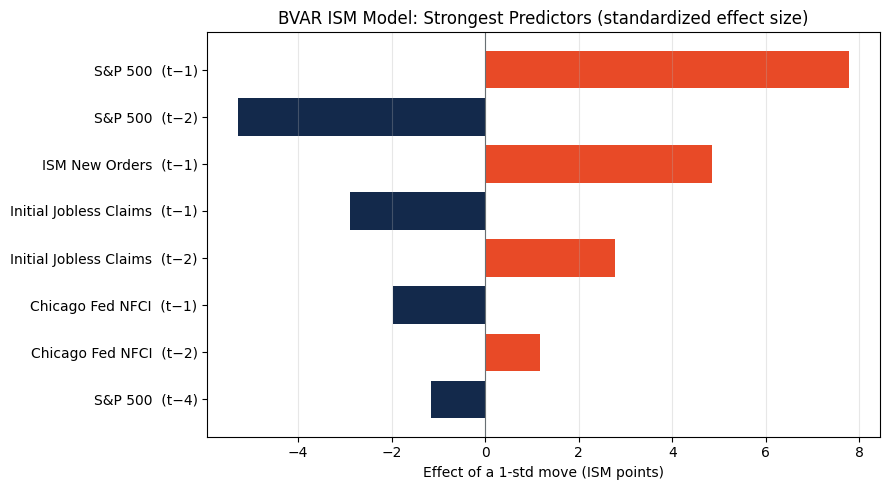

In [13]:
regressor_base = ism_coefs['regressor'].str.replace(r'_L\d+$', '', regex=True)
var_std = {col: Z[col].std() for col in Z.columns}

standardized = ism_coefs.copy()
standardized['base_var'] = regressor_base
standardized['std_effect'] = standardized['posterior_mean'] * standardized['base_var'].map(var_std)

top_ism = standardized[(standardized['regressor'] != 'const') & (~standardized['regressor'].str.startswith('covid_dummy'))].copy()
top_ism = top_ism.reindex(top_ism['std_effect'].abs().sort_values(ascending=False).index).head(8)
top_ism = top_ism.iloc[::-1]

ISM_VAR_LABELS = {
    'ISM': 'ISM New Orders',
    'T10Y2Y': '10Y–2Y Treasury Spread',
    'NFCI': 'Chicago Fed NFCI',
    'ICSA': 'Initial Jobless Claims',
    'SPX': 'S&P 500',
    'PERMIT': 'Building Permits',
}

def pretty_ism_label(row):
    base, lag = row['regressor'].rsplit('_L', 1)
    return f"{ISM_VAR_LABELS.get(base, base)}  (t−{lag})"

top_ism['label'] = top_ism.apply(pretty_ism_label, axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
colors = [illini_orange if v >= 0 else navy_blue for v in top_ism['std_effect']]
ax.barh(top_ism['label'], top_ism['std_effect'], color=colors)
ax.axvline(0, color=slate_grey, linewidth=0.8)
ax.set_xlabel('Effect of a 1-std move (ISM points)')
ax.set_title('BVAR ISM Model: Strongest Predictors (standardized effect size)')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

## 7. Export results

In [14]:
test_eval_df = pd.DataFrame({
    'date': dates_test,
    'actual': actual_test_ism,
    'bvar_median': best_fc[0.5].to_numpy(),
    'bvar_p05': best_fc[0.05].to_numpy(),
    'bvar_p16': best_fc[0.16].to_numpy(),
    'bvar_p84': best_fc[0.84].to_numpy(),
    'bvar_p95': best_fc[0.95].to_numpy(),
    'naive_random_walk': naive_rw,
    'naive_historical_mean': naive_mean,
}).set_index('date')

config_df = pd.DataFrame([
    {'parameter': 'variables', 'value': ', '.join(Z.columns)},
    {'parameter': 'dropped_variable', 'value': 'COPPER (near-zero ISM correlation + 12-month stale trailing gap)'},
    {'parameter': 'data_transformation', 'value': str(DATA_TRANSFORMATION)},
    {'parameter': 'covid_dates', 'value': str(COVID_DATES)},
    {'parameter': 'library', 'value': 'bvar (NaturalConjugate, Minnesota+SOC+SUR)'},
    {'parameter': 'optimisation_backend', 'value': BACKEND + ' (jax broken in this environment)'},
    {'parameter': 'test_size_months', 'value': TEST_SIZE},
    {'parameter': 'lag_order_candidates', 'value': str(P_GRID)},
    {'parameter': 'lag_order_selected', 'value': P_FINAL},
    {'parameter': 'final_c1', 'value': final_b.model.pars.c1},
    {'parameter': 'final_c3', 'value': final_b.model.pars.c3},
    {'parameter': 'final_mu', 'value': final_b.model.pars.mu},
    {'parameter': 'final_theta', 'value': final_b.model.pars.theta},
    {'parameter': 'forecast_horizon_months', 'value': FORECAST_HORIZON},
    {'parameter': 'test_rmse_24m_selected_p', 'value': float(best_row['rmse_24m'])},
    {'parameter': 'best_naive_rmse_24m', 'value': float(best_naive_rmse)},
])

Z_out = Z.copy()
Z_out.index = Z_out.index.astype(str)
Z_out.index.name = 'date'

with pd.ExcelWriter(OUTPUT_FILE, engine='openpyxl') as writer:
    ism_forecast.to_excel(writer, sheet_name='ISM_Forecast')
    comparison.to_excel(writer, sheet_name='Test_Evaluation', index=False)
    test_eval_df.to_excel(writer, sheet_name='Test_Forecast_BestP')
    horizon_errors.to_excel(writer, sheet_name='Horizon_Errors', index=False)
    ism_coefs.to_excel(writer, sheet_name='ISM_Equation_Coefs', index=False)
    config_df.to_excel(writer, sheet_name='Model_Config', index=False)
    Z_out.to_excel(writer, sheet_name='Model_Input_Data')

print(f"Wrote {OUTPUT_FILE}")

Wrote ISM_BVAR_Forecast.xlsx


In [15]:
import matplotlib.pyplot as plt

gs_colors = [
    "#0A1C2E",  # Goldman deep navy
    "#D4AF37",  # metallic gold
    "#4A4A4A",  # slate gray
    "#E6C76B",  # soft gold
]

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "grid.color": "#D0D0D0",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "lines.linewidth": 2.4,
    "lines.markersize": 6,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "legend.fontsize": 11,
    "axes.prop_cycle": plt.cycler(color=gs_colors)
})


In [16]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Fake dataset
dates = pd.date_range("2026-01-01", periods=24, freq="M")
df = pd.DataFrame({
    "sales": np.random.normal(100, 10, len(dates)),
    "costs": np.random.normal(80, 8, len(dates)),
    "profit": np.random.normal(20, 5, len(dates)),
}, index=dates)

# Fake correlation matrix
corr = df.corr()


C:\Users\Devminda\AppData\Local\Temp\ipykernel_24940\3816350290.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range("2026-01-01", periods=24, freq="M")


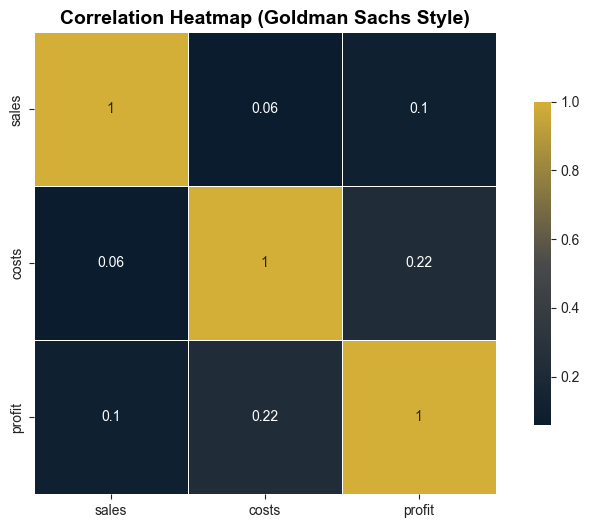

In [17]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

gs_cmap = LinearSegmentedColormap.from_list(
    "gs_map",
    ["#0A1C2E", "#4A4A4A", "#D4AF37"]
)

sns.heatmap(
    corr,
    annot=True,
    cmap=gs_cmap,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.7}
)
plt.title("Correlation Heatmap (Goldman Sachs Style)", fontsize=14, weight="bold")
plt.show()


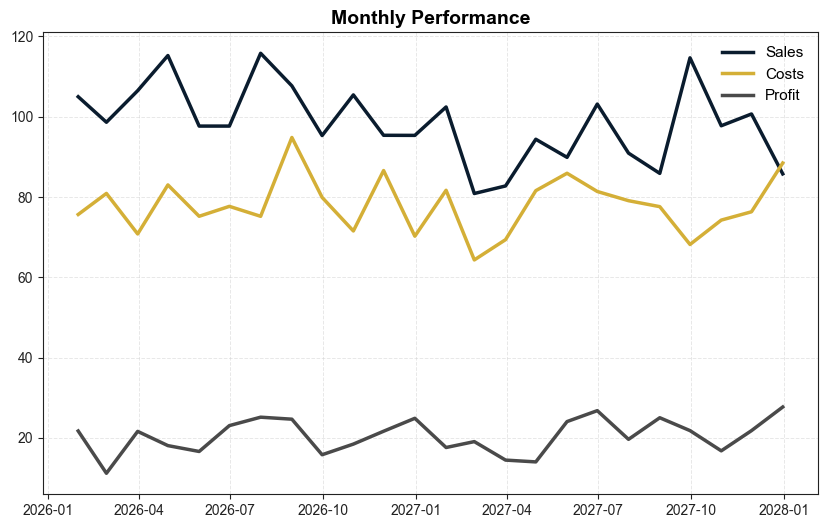

In [18]:
plt.figure(figsize=(10,6))
plt.plot(df.index, df["sales"], label="Sales", linewidth=2.5)
plt.plot(df.index, df["costs"], label="Costs", linewidth=2.5)
plt.plot(df.index, df["profit"], label="Profit", linewidth=2.5)

plt.title("Monthly Performance", fontsize=14, weight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()


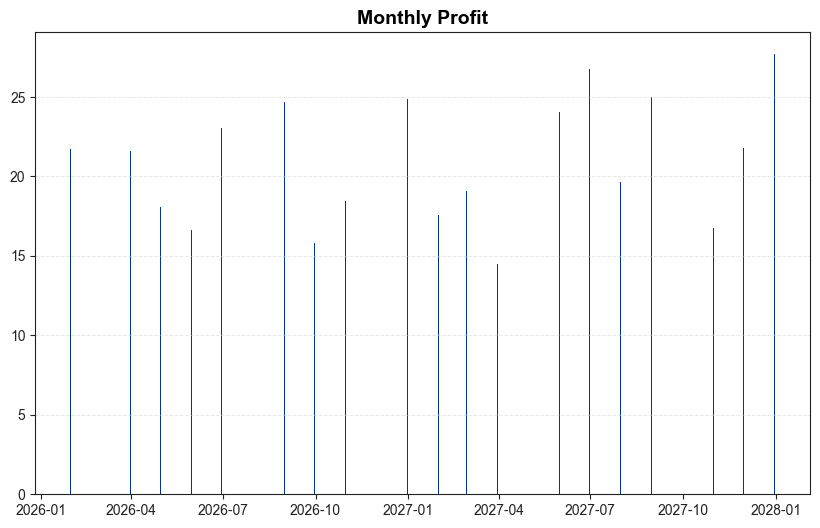

In [19]:
plt.figure(figsize=(10,6))
plt.bar(df.index, df["profit"], color="#0033A0")
plt.title("Monthly Profit", fontsize=14, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


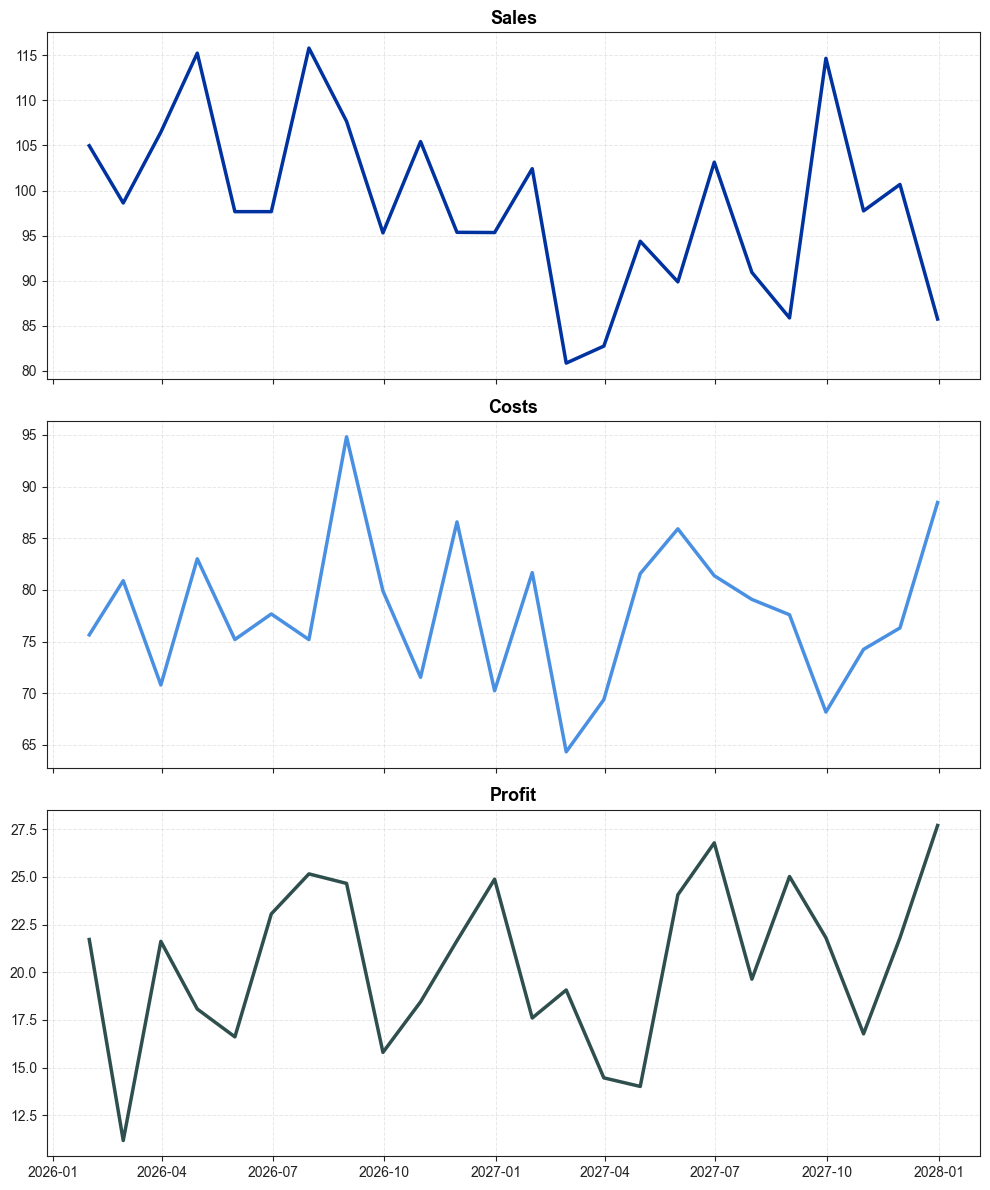

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(10,12), sharex=True)

ax[0].plot(df.index, df["sales"], color="#0033A0", linewidth=2.5)
ax[0].set_title("Sales", fontsize=13, weight="bold")

ax[1].plot(df.index, df["costs"], color="#4A90E2", linewidth=2.5)
ax[1].set_title("Costs", fontsize=13, weight="bold")

ax[2].plot(df.index, df["profit"], color="#2F4F4F", linewidth=2.5)
ax[2].set_title("Profit", fontsize=13, weight="bold")

for a in ax:
    a.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
